COMPROBACION: precios recalculados contra resumen_fase9.csv


  Caso A: coincide en las 100 cadenas = True


  Caso B: coincide en las 100 cadenas = True


  Caso C: coincide en las 100 cadenas = True


  Caso D: coincide en las 100 cadenas = True



C(l) de las series binarias, l = 1 a 8; ajuste con l >= 2


... (14 outputs left out)

Caso D mansilla  burn-in=1000: omitidos por cadena=  145.1  largo= 4853.9  fraccion de subidas=0.498  C(2)=8.239e-02  C(8)=7.268e-01  alpha=1.5428  beta=3.098e-02  R2=0.9935


Caso D acumulado burn-in=1000: omitidos por cadena=  538.7  largo= 4461.3  fraccion de subidas=0.494  C(2)=1.095e-02  C(8)=1.450e-01  alpha=1.8527  beta=2.915e-03  R2=0.9987



Guardado: csv\Fase9_resumen_CK_precios_binarios_N101_s2_T6000_regla_nueva.csv

Graficas:


  Guardado: graficas\Fase9_CK_contra_l_precios_binarios_N101_s2_T6000_regla_nueva.png


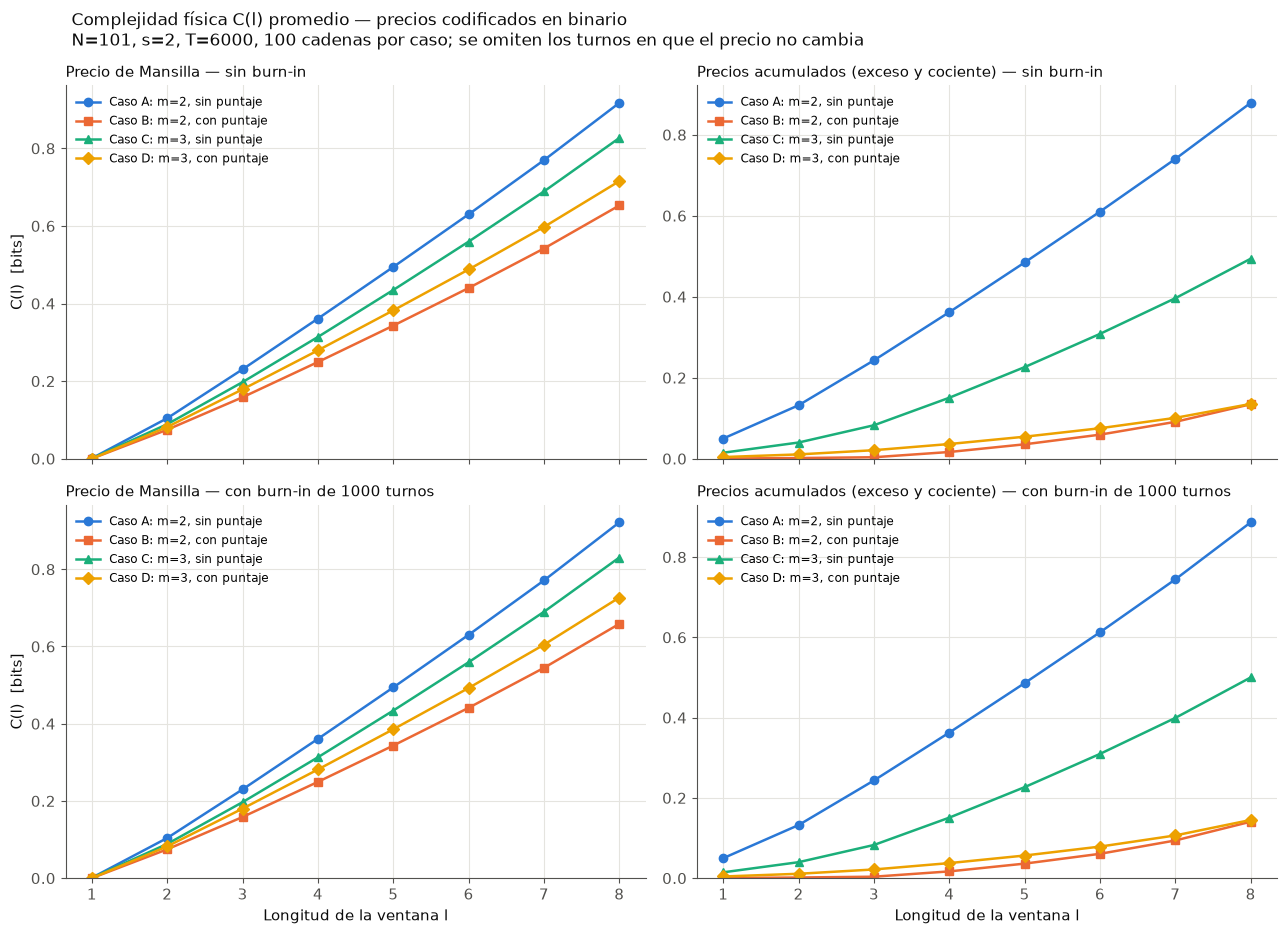

  Guardado: graficas\Fase9_CK_loglog_precios_binarios_N101_s2_T6000_regla_nueva.png


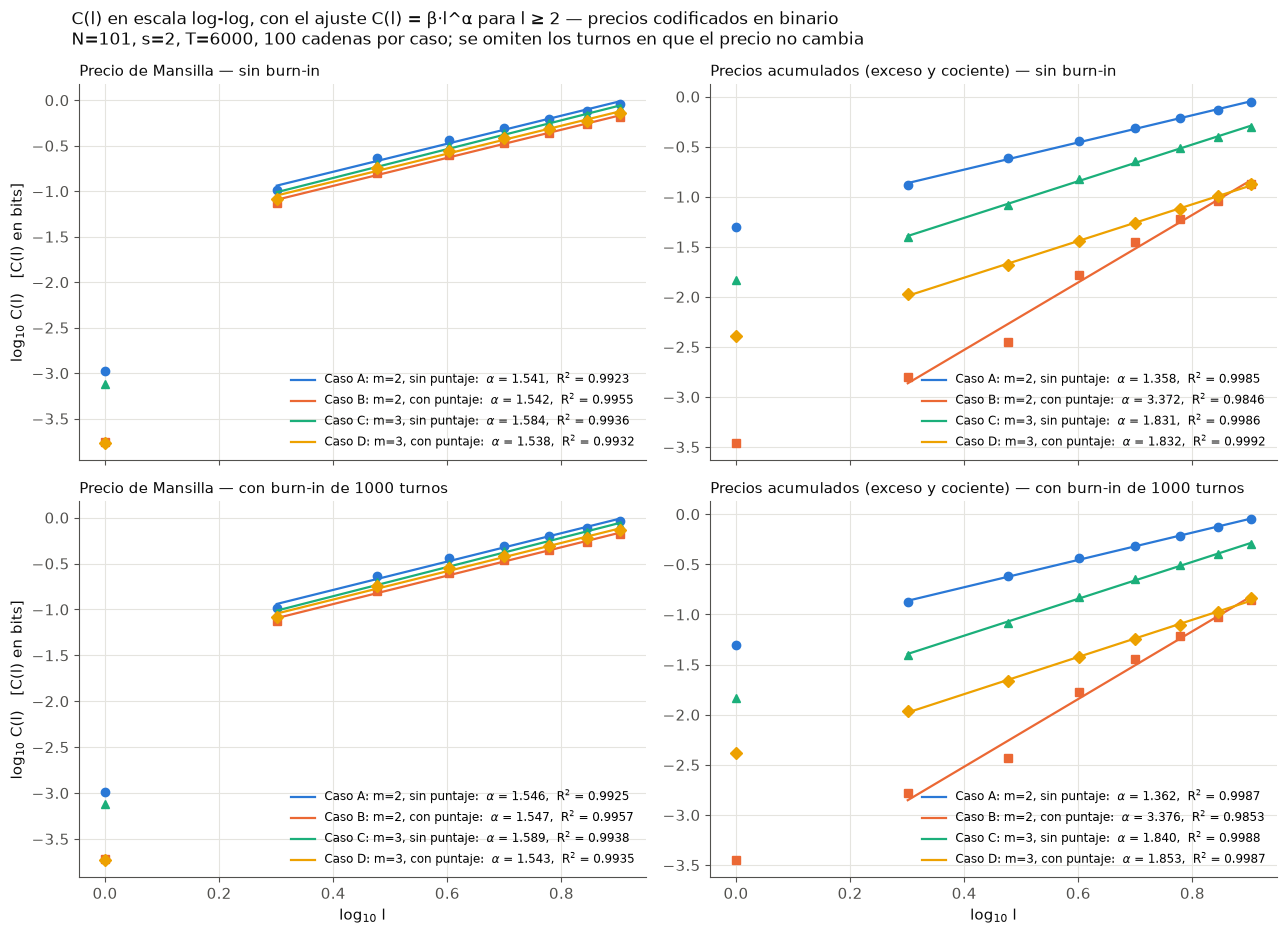


Listo. Tiempo total: 0.1 min


In [1]:
"""
FASE 9 (segunda parte) - Complejidad fisica de los precios codificados en binario
==================================================================
Tesis: Complejidad e informacion en un minority game con opcion de abstencion
Base: R. Mansilla, Physica A 301, 483 (2001)

No simula: lee los conteos N0, N1, N2 de la Fase 9 (0 = comprar, 1 = vender,
2 = abstenerse).

Que hace este codigo:
  0. COMPROBACION: recalcula los precios acumulados de las 400 cadenas y los
     compara con resumen_fase9.csv. Si no coinciden, el notebook se detiene.
  1. Codifica cada precio en una serie binaria, como en el articulo:
        1 si el precio subio respecto al turno anterior, 0 si bajo.
     Los turnos en que el precio NO cambio se omiten (decision de Hector; el
     articulo no dice que hacer en ese caso).
  2. Hay dos series binarias distintas:
        "mansilla"  : sube si N0/N1 es mayor que en el turno anterior.
        "acumulado" : sube si N0 > N1 en ese turno. Los precios de exceso de
                      demanda y de cociente suben en los mismos turnos, asi que
                      dan la misma serie (el codigo lo verifica).
  3. A cada serie le calcula C(l) = l*log2(2) - H(l), l = 1, ..., L_MAX, y
     promedia sobre las 100 cadenas.
  4. Ajusta C(l) = beta * l^alpha en log-log (np.polyfit de grado 1) con
     l >= L_MIN_AJUSTE, quitando solo los puntos con C(l) = 0.
  Todo se hace dos veces: sin burn-in y con burn-in.

complejidad_fisica y resumir son las de la Fase 8, sin cambios. precio_mansilla,
rendimiento_exceso, rendimiento_cociente, acumular y terminar_figura son las
de la Fase 9, sin cambios.
"""

import os
import time

import numpy as np
import matplotlib.pyplot as plt

try:
    from scipy.stats import t as t_student
except ImportError:
    t_student = None
T_95 = 1.984  # t de Student, 95%, 99 g.l. (por si no hay scipy)


# =====================================================================
# OPCIONES
# =====================================================================
# Las graficas SIEMPRE se muestran en el notebook.
DESCARGAR_GRAFICAS = True     # True = ademas se guardan como PNG
GUARDAR_CSV        = True     # True = se guarda el CSV de resumen

CARPETA_CSV       = "csv"
CARPETA_GRAFICAS  = "graficas"
CARPETA_CSV_FASE9 = "csv"   # los conteos de esta misma fase; solo se leen


# =====================================================================
# PARAMETROS  (los de la Fase 9)
# =====================================================================
N_CADENAS = 100
N       = 101
S       = 2
K       = 3
T       = 6000
BURN_IN = 1000
REGLA   = "regla_nueva"

CASOS = [{"caso": "A", "m": 2, "puntaje": False}, {"caso": "B", "m": 2, "puntaje": True}, {"caso": "C", "m": 3, "puntaje": False}, {"caso": "D", "m": 3, "puntaje": True}]
SERIES = ["mansilla", "acumulado"]

LAMBDA_EXCESO   = N
LAMBDA_COCIENTE = np.log(N + 1)

K_BIN         = 2     # alfabeto de la serie codificada: 0 = bajo, 1 = subio
L_MAX         = 8     # C(l) se calcula para l = 1, ..., L_MAX
L_MIN_AJUSTE  = 2     # el ajuste usa l >= 2, como en el articulo
NIVEL         = 0.95


# =====================================================================
# PRECIOS  (igual que en la Fase 9)
# =====================================================================
def precio_mansilla(N0, N1):
    """p_t = arctan(N0/N1), con np.arctan2(N0, N1).

    Nadie vende  (N1 = 0, N0 > 0): pi/2.   Nadie compra (N0 = 0, N1 > 0): 0.
    Nadie compra ni vende (N0 = N1 = 0): se repite el precio anterior
    (si es el primer turno, pi/4).
    """
    p = np.arctan2(N0, N1).astype(float)
    for t in np.flatnonzero((N0 == 0) & (N1 == 0)):
        p[t] = p[t - 1] if t > 0 else np.pi / 4
    return p


def rendimiento_exceso(N0, N1):
    return (N0 - N1) / LAMBDA_EXCESO


def rendimiento_cociente(N0, N1):
    return np.log((N0 + 1) / (N1 + 1)) / LAMBDA_COCIENTE


def acumular(rendimientos, inicio):
    """ln p desde el turno 'inicio', empezando en ln p = 0. Tiene un punto
    mas que turnos: el ultimo es el precio despues del ultimo turno."""
    return np.concatenate([[0.0], np.cumsum(rendimientos[inicio:])])


# =====================================================================
# CODIFICACION BINARIA  (1 = el precio subio, 0 = bajo; sin cambio = se omite)
# =====================================================================
def binaria_acumulado(N0, N1, inicio):
    """Precios acumulados: el precio sube en el turno t si N0 > N1 y baja si
    N0 < N1. Si N0 = N1 no cambia y el turno se omite.
    Devuelve la serie binaria y cuantos turnos se omitieron."""
    diferencia = N0[inicio:].astype(np.int64) - N1[inicio:].astype(np.int64)
    conserva = diferencia != 0
    return (diferencia[conserva] > 0).astype(np.int64), int((~conserva).sum())


def binaria_mansilla(N0, N1, inicio):
    """Precio de Mansilla, p_t = arctan(N0/N1): sube si N0/N1 es mayor que en
    el turno anterior. La comparacion se hace con enteros,
        N0[t]*N1[t-1]  contra  N0[t-1]*N1[t],
    que equivale a comparar los cocientes sin errores de redondeo.
    Si N0 = N1 = 0 se usa el turno anterior (el precio se repite), como en la
    Fase 9. Devuelve la serie binaria y cuantos turnos se omitieron."""
    a = N0.astype(np.int64).copy()
    b = N1.astype(np.int64).copy()
    for t in np.flatnonzero((a == 0) & (b == 0)):
        a[t], b[t] = (a[t - 1], b[t - 1]) if t > 0 else (1, 1)
    a, b = a[inicio:], b[inicio:]
    cruz = a[1:] * b[:-1] - a[:-1] * b[1:]
    conserva = cruz != 0
    return (cruz[conserva] > 0).astype(np.int64), int((~conserva).sum())


# =====================================================================
# COMPLEJIDAD FISICA  (igual que en la Fase 8)
# =====================================================================
def complejidad_fisica(serie, l, K):
    """Devuelve C_K(l) y c_K(l) de una cadena de ganadores.

    Una ventana de longitud l recorre la cadena de uno en uno. Cada ventana
    se convierte en un numero (en base K) para contar cuantas veces aparece
    cada subcadena eta. Con esas frecuencias relativas p(eta):

        H(l)   = -sum p(eta) log2 p(eta)
        C_K(l) = l*log2(K) - H(l)
        c_K(l) = C_K(l) / (l*log2(K))
    """
    ventanas = np.lib.stride_tricks.sliding_window_view(serie, l)
    pesos = K ** np.arange(l - 1, -1, -1)
    codigos = ventanas @ pesos
    conteos = np.bincount(codigos, minlength=K ** l)

    p = conteos[conteos > 0] / len(codigos)
    H = -np.sum(p * np.log2(p))

    maximo = l * np.log2(K)
    C = maximo - H
    return C, C / maximo


def resumir(tabla, t_crit):
    """Promedio sobre las cadenas (filas), con su intervalo de confianza."""
    media = tabla.mean(axis=0)
    desv = tabla.std(axis=0, ddof=1)
    error_est = desv / np.sqrt(tabla.shape[0])
    return {"media": media, "desv": desv, "error_est": error_est,
            "ic_inf": media - t_crit * error_est,
            "ic_sup": media + t_crit * error_est}


def ajuste_potencia(longitudes, C):
    """Ajuste de C(l) = beta * l^alpha: recta en log10 C contra log10 l."""
    usar = (longitudes >= L_MIN_AJUSTE) & (C > 0)
    x, y = np.log10(longitudes[usar]), np.log10(C[usar])
    alpha, ordenada = np.polyfit(x, y, 1)
    y_ajuste = alpha * x + ordenada
    r2 = 1 - np.sum((y - y_ajuste) ** 2) / np.sum((y - y.mean()) ** 2)
    return {"alpha": alpha, "beta": 10 ** ordenada, "r2": r2, "x": x, "y": y,
            "y_ajuste": y_ajuste, "puntos": int(usar.sum())}


# =====================================================================
# LEER LA FASE 9
# =====================================================================
def nombre_base(caso):
    texto = "con_puntaje" if caso["puntaje"] else "sin_puntaje"
    return f"caso{caso['caso']}_N{N}_m{caso['m']}_s{S}_{texto}_T{T}_{REGLA}"


def leer_conteos(caso):
    """Devuelve conteos[cadena, turno, opcion] del CSV largo de la Fase 9."""
    tabla = np.loadtxt(os.path.join(CARPETA_CSV_FASE9,
                                    f"Fase9_conteos_{nombre_base(caso)}.csv"),
                       delimiter=",", skiprows=1, dtype=np.int64)
    if not (len(tabla) == N_CADENAS * T
            and np.array_equal(tabla[:, 0], np.repeat(np.arange(N_CADENAS), T))
            and np.array_equal(tabla[:, 2], np.tile(np.arange(T), N_CADENAS))):
        raise RuntimeError("El CSV de conteos no tiene el orden esperado")
    return tabla[:, 3:6].reshape(N_CADENAS, T, K)


def comprobacion(conteos_por_caso):
    print("COMPROBACION: precios recalculados contra resumen_fase9.csv", flush=True)
    resumen = np.genfromtxt(os.path.join(CARPETA_CSV_FASE9, "resumen_fase9.csv"),
                            delimiter=",", comments="#", skip_header=4, dtype=None,
                            encoding="utf8")
    fila = 0
    for caso in CASOS:
        conteos = conteos_por_caso[caso["caso"]].astype(float)
        iguales = True
        for c in range(N_CADENAS):
            n0, n1 = conteos[c, :, 0], conteos[c, :, 1]
            exc = acumular(rendimiento_exceso(n0, n1), 0)
            coc = acumular(rendimiento_cociente(n0, n1), 0)
            guardado = [resumen[fila][j] for j in range(13, 19)]
            iguales &= resumen[fila][0] == caso["caso"] and np.allclose(
                [exc[-1], exc.max(), exc.min(), coc[-1], coc.max(), coc.min()],
                guardado, rtol=1e-7, atol=1e-9)
            fila += 1
        print(f"  Caso {caso['caso']}: coincide en las {N_CADENAS} cadenas = {bool(iguales)}",
              flush=True)
        if not iguales:
            raise RuntimeError("COMPROBACION FALLIDA: los precios recalculados no "
                               "coinciden con resumen_fase9.csv.")


# =====================================================================
# GRAFICAS
# =====================================================================
COLORES = dict(zip("ABCD", ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
MARCAS = dict(zip("ABCD", ["o", "s", "^", "D"]))
GRIS = "#52514e"
TINTA = "#0b0b0b"
TITULO_SERIE = {"mansilla": "Precio de Mansilla",
                "acumulado": "Precios acumulados (exceso y cociente)"}


def terminar_figura(fig, archivo):
    if DESCARGAR_GRAFICAS:
        ruta = os.path.join(CARPETA_GRAFICAS, archivo)
        fig.savefig(ruta, dpi=150)
        print(f"  Guardado: {ruta}", flush=True)
    plt.show()
    plt.close(fig)


def etiqueta_caso(caso):
    return (f"Caso {caso['caso']}: m={caso['m']}, "
            f"{'con' if caso['puntaje'] else 'sin'} puntaje")


def texto_burn(inicio):
    return f"con burn-in de {inicio} turnos" if inicio else "sin burn-in"


def graficar(resultados, longitudes, loglog):
    """Filas: sin y con burn-in. Columnas: las dos series binarias."""
    fig, ejes = plt.subplots(2, 2, figsize=(13, 9.5), sharex=True)
    for i, inicio in enumerate((0, BURN_IN)):
        for j, serie in enumerate(SERIES):
            ax = ejes[i, j]
            for caso in CASOS:
                r = resultados[(caso["caso"], serie, inicio)]
                color, marca = COLORES[caso["caso"]], MARCAS[caso["caso"]]
                if loglog:
                    aj = r["ajuste"]
                    ax.plot(np.log10(longitudes[r["C"]["media"] > 0]),
                            np.log10(r["C"]["media"][r["C"]["media"] > 0]),
                            marca, color=color, ms=6)
                    ax.plot(aj["x"], aj["y_ajuste"], color=color, lw=1.6,
                            label=(f"{etiqueta_caso(caso)}:  "
                                   f"$\\alpha$ = {aj['alpha']:.3f},  R$^2$ = {aj['r2']:.4f}"))
                else:
                    ax.plot(longitudes, r["C"]["media"], color=color, marker=marca,
                            ms=6, lw=1.8, label=etiqueta_caso(caso))
            ax.set_title(f"{TITULO_SERIE[serie]} — {texto_burn(inicio)}", loc="left",
                         color=TINTA, fontsize=11)
            ax.grid(color="#e5e4df", lw=0.8)
            ax.legend(frameon=False, fontsize=8.5,
                      loc="lower right" if loglog else "upper left")
            if i == 1:
                ax.set_xlabel("log$_{10}$ l" if loglog else "Longitud de la ventana l")
            if j == 0:
                ax.set_ylabel("log$_{10}$ C(l)   [C(l) en bits]" if loglog else "C(l)  [bits]")
            if not loglog:
                ax.set_xticks(longitudes)
                ax.set_ylim(bottom=0)
    que = ("C(l) en escala log-log, con el ajuste C(l) = β·l^α para l ≥ "
           f"{L_MIN_AJUSTE}" if loglog else "Complejidad física C(l) promedio")
    fig.suptitle(f"{que} — precios codificados en binario\n"
                 f"N={N}, s={S}, T={T}, {N_CADENAS} cadenas por caso; se omiten los turnos "
                 "en que el precio no cambia", x=0.06, ha="left", color=TINTA, fontsize=12)
    fig.tight_layout()
    nombre = "loglog" if loglog else "contra_l"
    terminar_figura(fig, f"Fase9_CK_{nombre}_precios_binarios_N{N}_s{S}_T{T}_{REGLA}.png")


# =====================================================================
# PROGRAMA PRINCIPAL
# =====================================================================
if __name__ == "__main__":
    inicio_reloj = time.time()
    longitudes = np.arange(1, L_MAX + 1)
    t_crit = (t_student.ppf(0.5 + NIVEL / 2, N_CADENAS - 1)
              if t_student is not None else T_95)

    if GUARDAR_CSV:
        os.makedirs(CARPETA_CSV, exist_ok=True)
    if DESCARGAR_GRAFICAS:
        os.makedirs(CARPETA_GRAFICAS, exist_ok=True)
    plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRIS,
                         "axes.labelcolor": TINTA, "xtick.color": GRIS,
                         "ytick.color": GRIS, "axes.spines.top": False,
                         "axes.spines.right": False})

    conteos_por_caso = {caso["caso"]: leer_conteos(caso) for caso in CASOS}
    comprobacion(conteos_por_caso)

    resultados = {}
    filas = []
    print(f"\nC(l) de las series binarias, l = 1 a {L_MAX}; ajuste con l >= {L_MIN_AJUSTE}",
          flush=True)
    for caso in CASOS:
        conteos = conteos_por_caso[caso["caso"]]
        for inicio in (0, BURN_IN):
            for serie in SERIES:
                tabla = np.zeros((N_CADENAS, L_MAX))
                omitidos = np.zeros(N_CADENAS)
                largo = np.zeros(N_CADENAS)
                unos = np.zeros(N_CADENAS)
                for c in range(N_CADENAS):
                    N0, N1 = conteos[c, :, 0], conteos[c, :, 1]
                    if serie == "mansilla":
                        binaria, omitidos[c] = binaria_mansilla(N0, N1, inicio)
                    else:
                        binaria, omitidos[c] = binaria_acumulado(N0, N1, inicio)
                        # el cociente sube en los mismos turnos que el exceso
                        r_coc = rendimiento_cociente(N0[inicio:].astype(float),
                                                     N1[inicio:].astype(float))
                        if not np.array_equal(binaria, (r_coc[r_coc != 0] > 0).astype(np.int64)):
                            raise RuntimeError("Exceso y cociente no dan la misma serie binaria")
                    largo[c] = len(binaria)
                    unos[c] = binaria.mean()
                    tabla[c] = [complejidad_fisica(binaria, l, K_BIN)[0] for l in longitudes]
                rC = resumir(tabla, t_crit)
                aj = ajuste_potencia(longitudes, rC["media"])
                resultados[(caso["caso"], serie, inicio)] = {"C": rC, "ajuste": aj}
                print(f"Caso {caso['caso']} {serie:9s} burn-in={inicio:4d}: "
                      f"omitidos por cadena={omitidos.mean():7.1f}  largo={largo.mean():7.1f}  "
                      f"fraccion de subidas={unos.mean():.3f}  C(2)={rC['media'][1]:.3e}  "
                      f"C({L_MAX})={rC['media'][-1]:.3e}  alpha={aj['alpha']:.4f}  "
                      f"beta={aj['beta']:.3e}  R2={aj['r2']:.4f}", flush=True)
                filas.append([caso["caso"], caso["m"], int(caso["puntaje"]), N,
                              K ** caso["m"] / N, serie, inicio, omitidos.mean(),
                              largo.mean(), unos.mean(), *rC["media"], aj["alpha"],
                              aj["beta"], aj["r2"], aj["puntos"]])

    if GUARDAR_CSV:
        ruta = os.path.join(CARPETA_CSV,
                            f"Fase9_resumen_CK_precios_binarios_N{N}_s{S}_T{T}_{REGLA}.csv")
        with open(ruta, "w", encoding="utf8") as archivo:
            archivo.write(f"# FASE 9. C(l) de los precios codificados en binario (1 = subio, 0 = bajo; "
                          f"sin cambio = turno omitido). N={N} s={S} T={T} cadenas={N_CADENAS}\n"
                          f"# Promedios sobre las cadenas. Ajuste C(l) = beta*l^alpha con l >= {L_MIN_AJUSTE}.\n"
                          "caso,m,puntaje,N,gamma,serie,burn_in,turnos_omitidos_promedio,"
                          "longitud_promedio,fraccion_subidas,"
                          + ",".join(f"C_l{l}" for l in longitudes)
                          + ",alpha,beta,R2,puntos_ajuste\n")
            for f in filas:
                archivo.write(",".join([f[0], str(f[1]), str(f[2]), str(f[3]), f"{f[4]:.6f}",
                                        f[5], str(f[6])]
                                       + [f"{v:.8e}" for v in f[7:-1]] + [str(f[-1])]) + "\n")
        print(f"\nGuardado: {ruta}")

    print("\nGraficas:")
    graficar(resultados, longitudes, loglog=False)
    graficar(resultados, longitudes, loglog=True)
    print(f"\nListo. Tiempo total: {(time.time() - inicio_reloj) / 60:.1f} min")
